# 🚀 Kaggle Kick-start Workshop - Day 2
## From Data to Winning Submissions: Model Training Mastery

**Duration:** 3 hours

---

## What You'll Learn Today

By the end of today:
- ✅ Build professional ML pipelines using sklearn
- ✅ Train and evaluate multiple models
- ✅ Understand Bias-Variance tradeoff
- ✅ Master hyperparameter tuning techniques
- ✅ Learn Kaggle pro tips and tricks
- ✅ Submit predictions with confidence!

---

## 📋 Session Plan

| Time | Topic | Duration |
|------|-------|----------|
| 2:00-2:20 PM | Pipeline & ColumnTransformer Setup | 20 min |
| 2:20-2:45 PM | First Model + Evaluation Metrics | 25 min |
| 2:45-3:15 PM | Model Benchmarking (Multiple Models) | 30 min |
| 3:15-3:25 PM | **BREAK** | 10 min |
| 3:25-3:50 PM | Bias, Variance, Over/Underfitting | 25 min |
| 3:50-4:20 PM | Hyperparameter Tuning | 30 min |
| 4:20-4:45 PM | Advanced Techniques & Ensemble Methods | 25 min |
| 4:45-5:00 PM | Kaggle Submission + Pro Tips | 15 min |

---

## 🎯 The ML Pipeline Mindset

```
Data → Preprocessing → Model → Evaluation → Tuning → Submission
       (Pipeline)     (Train)  (Validate)   (Optimize)
```

**Why Pipelines?**
1. **No Data Leakage** - Preprocessing fit only on training data
2. **Reproducibility** - Same transformations for train/test
3. **Clean Code** - Everything in one object
4. **Easy Deployment** - Save and load entire workflow


---

## 1. Setup & Load Data from Day 1

### Import All Required Libraries


In [1]:
# Core Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Sklearn - Preprocessing
from sklearn.model_selection import (
    train_test_split, cross_val_score, StratifiedKFold,
    GridSearchCV, RandomizedSearchCV, learning_curve
)
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer

# Sklearn - Pipeline & ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer, make_column_transformer

# Sklearn - Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier,
    AdaBoostClassifier, ExtraTreesClassifier, VotingClassifier,
    BaggingClassifier, StackingClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# Sklearn - Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    roc_curve, precision_recall_curve, make_scorer
)

# Display settings
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

print("✅ All libraries imported successfully!")


✅ All libraries imported successfully!


### Load Titanic Data (Repeat Day 1 Preprocessing)

We'll recreate our processed data from Day 1 and then build pipelines on top of it.


In [3]:
# Load raw data
train = pd.read_csv('data/train.csv')
test = pd.read_csv('data/test.csv')

# Store PassengerId for submission later
test_passenger_ids = test['PassengerId']

print(f"Training set: {train.shape}")
print(f"Test set: {test.shape}")
train.head()


Training set: (891, 12)
Test set: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### Apply Day 1 Feature Engineering

Let's quickly recreate all the features we engineered on Day 1:


In [ ]:
def preprocess_data(df, is_train=True):
    """
    Apply all Day 1 feature engineering in one function
    """
    df = df.copy()
    
    # ============= Feature Engineering =============
    
    # 1. Extract Title from Name
    df['Title'] = df['Name'].str.split(', ').str[1].str.split('.').str[0]
    
    # Group rare titles
    rare_titles = ['Dr', 'Rev', 'Col', 'Major', 'Capt', 'Sir', 'Lady', 
                   'Don', 'Jonkheer', 'the Countess', 'Dona']
    df['Title'] = df['Title'].replace(rare_titles, 'Rare')
    df['Title'] = df['Title'].replace(['Mlle', 'Ms'], 'Miss')
    df['Title'] = df['Title'].replace('Mme', 'Mrs')
    
    # 2. Family Size
    df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
    
    # 3. Is Alone
    df['IsAlone'] = (df['FamilySize'] == 1).astype(int)
    
    # 4. Has Cabin
    df['HasCabin'] = df['Cabin'].notna().astype(int)
    
    # 5. Deck from Cabin (First letter)
    df['Deck'] = df['Cabin'].str[0].fillna('U')  # U = Unknown
    
    # ============= Handle Missing Values =============
    
    # Fill Embarked with mode
    df['Embarked'] = df['Embarked'].fillna('S')
    
    # Fill Fare with median by Pclass
    df['Fare'] = df.groupby('Pclass')['Fare'].transform(
        lambda x: x.fillna(x.median())
    )
    
    # Fill Age using Title median (smart imputation)
    title_age_median = df.groupby('Title')['Age'].transform('median')
    df['Age'] = df['Age'].fillna(title_age_median)
    
    # If still missing (rare edge case), use overall median
    df['Age'] = df['Age'].fillna(df['Age'].median())
    
    # ============= Create Age Groups =============
    bins = [0, 5, 12, 18, 25, 35, 60, 100]
    labels = ['Baby', 'Child', 'Teen', 'Student', 'YoungAdult', 'Adult', 'Senior']
    df['AgeGroup'] = pd.cut(df['Age'], bins=bins, labels=labels)
    
    # ============= Create Fare Groups =============
    df['FareGroup'] = pd.qcut(df['Fare'].clip(upper=100), q=4, 
                               labels=['Low', 'Medium', 'High', 'VeryHigh'])
    
    return df

# Apply preprocessing to both datasets
train_processed = preprocess_data(train, is_train=True)
test_processed = preprocess_data(test, is_train=False)

print("✅ Feature engineering complete!")
print(f"\nNew features created:")
print(train_processed.columns.tolist())

✅ Feature engineering complete!

New features created:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'Title', 'FamilySize', 'IsAlone', 'HasCabin', 'Deck', 'AgeGroup', 'FareGroup']


In [5]:
# Check the processed data
train_processed.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title,FamilySize,IsAlone,HasCabin,Deck,AgeGroup,FareGroup
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Mr,2,0,0,U,Student,Low
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Mrs,2,0,1,C,Adult,VeryHigh
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Miss,1,1,0,U,YoungAdult,Medium
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Mrs,2,0,1,C,YoungAdult,VeryHigh
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Mr,1,1,0,U,YoungAdult,Medium


---

## 2. Professional sklearn Pipeline Setup

### 🎯 Why Use Pipelines?

**Without Pipeline (Bad Practice):**
```python
# Dangerous! Can cause data leakage
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)  # Easy to forget!
model.fit(X_train_scaled, y_train)
```

**With Pipeline (Professional):**
```python
# Safe and clean!
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression())
])
pipeline.fit(X_train, y_train)  # Does everything correctly!
```

### Define Feature Groups

Professional Kagglers organize features by type:


In [6]:
# ============= Define Feature Groups =============

# Numerical features (continuous values) - need scaling
numerical_features = ['Age', 'Fare', 'FamilySize']

# Categorical features (discrete values) - need encoding
categorical_features = ['Sex', 'Embarked', 'Title', 'Deck']

# Ordinal features (categories with order) - can use ordinal encoding
ordinal_features = ['Pclass', 'AgeGroup', 'FareGroup']

# Binary features (already 0/1) - no transformation needed
binary_features = ['IsAlone', 'HasCabin']

# All features combined
all_features = numerical_features + categorical_features + ordinal_features + binary_features

print("📊 Feature Groups:")
print(f"   Numerical ({len(numerical_features)}): {numerical_features}")
print(f"   Categorical ({len(categorical_features)}): {categorical_features}")
print(f"   Ordinal ({len(ordinal_features)}): {ordinal_features}")
print(f"   Binary ({len(binary_features)}): {binary_features}")
print(f"\n   Total features: {len(all_features)}")


📊 Feature Groups:
   Numerical (3): ['Age', 'Fare', 'FamilySize']
   Categorical (4): ['Sex', 'Embarked', 'Title', 'Deck']
   Ordinal (3): ['Pclass', 'AgeGroup', 'FareGroup']
   Binary (2): ['IsAlone', 'HasCabin']

   Total features: 12


### Build the ColumnTransformer

**ColumnTransformer** applies different transformations to different columns:
- Numerical → StandardScaler
- Categorical → OneHotEncoder  
- Ordinal → OrdinalEncoder
- Binary → Pass through (no change)


In [7]:
# ============= Build Professional ColumnTransformer =============

# Numerical transformer: Scale to mean=0, std=1
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),  # Handle any remaining NaN
    ('scaler', StandardScaler())
])

# Categorical transformer: One-hot encode (creates dummy variables)
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Ordinal transformer: Encode as ordered integers
ordinal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])

# Combine all transformers
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features),
        ('ord', ordinal_transformer, ordinal_features),
        ('bin', 'passthrough', binary_features)  # No transformation needed
    ],
    remainder='drop'  # Drop any columns not specified
)

print("✅ ColumnTransformer created!")
print("\n📋 Pipeline structure:")
print("""
┌─────────────────────────────────────────────────────────────┐
│                    ColumnTransformer                        │
├─────────────────────────────────────────────────────────────┤
│  Numerical    → Imputer(median) → StandardScaler           │
│  Categorical  → Imputer(constant) → OneHotEncoder          │
│  Ordinal      → Imputer(mode) → OrdinalEncoder             │
│  Binary       → Passthrough (no change)                    │
└─────────────────────────────────────────────────────────────┘
""")


✅ ColumnTransformer created!

📋 Pipeline structure:

┌─────────────────────────────────────────────────────────────┐
│                    ColumnTransformer                        │
├─────────────────────────────────────────────────────────────┤
│  Numerical    → Imputer(median) → StandardScaler           │
│  Categorical  → Imputer(constant) → OneHotEncoder          │
│  Ordinal      → Imputer(mode) → OrdinalEncoder             │
│  Binary       → Passthrough (no change)                    │
└─────────────────────────────────────────────────────────────┘



### Prepare Data for Training

In [8]:
# ============= Prepare X and y =============

# Features (X) and Target (y)
X = train_processed[all_features]
y = train_processed['Survived']

# Test set (no target - that's what we predict!)
X_test_final = test_processed[all_features]

# ============= Train-Validation Split =============
# Use stratified split to maintain class balance

X_train, X_val, y_train, y_val = train_test_split(
    X, y, 
    test_size=0.2,           # 20% for validation
    random_state=42,         # Reproducibility
    stratify=y               # Maintain class balance!
)

print("📊 Data Split:")
print(f"   Training set: {X_train.shape[0]} samples")
print(f"   Validation set: {X_val.shape[0]} samples")
print(f"   Test set (final): {X_test_final.shape[0]} samples")
print(f"\n   Target distribution (train): {y_train.value_counts().to_dict()}")
print(f"   Target distribution (val): {y_val.value_counts().to_dict()}")


📊 Data Split:
   Training set: 712 samples
   Validation set: 179 samples
   Test set (final): 418 samples

   Target distribution (train): {0: 439, 1: 273}
   Target distribution (val): {0: 110, 1: 69}


---

## 3. First Model - The Baseline

### 🎯 Pro Tip: Always Start Simple!

Professional Kagglers **always** start with a simple baseline model because:
1. Quick feedback loop
2. Helps identify data issues
3. Sets a benchmark to beat
4. Sometimes simple wins!

### Create Full Pipeline (Preprocessing + Model)


In [9]:
# ============= Create Full Pipeline =============

# Baseline model: Logistic Regression (simple, interpretable)
baseline_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# Train the model
baseline_pipeline.fit(X_train, y_train)

# Make predictions
y_train_pred = baseline_pipeline.predict(X_train)
y_val_pred = baseline_pipeline.predict(X_val)

print("✅ Baseline model trained!")
print(f"\n📈 Quick Results:")
print(f"   Training Accuracy: {accuracy_score(y_train, y_train_pred):.4f}")
print(f"   Validation Accuracy: {accuracy_score(y_val, y_val_pred):.4f}")


✅ Baseline model trained!

📈 Quick Results:
   Training Accuracy: 0.8385
   Validation Accuracy: 0.8492


---

## 4. Model Evaluation Metrics

### 📊 Understanding Classification Metrics

| Metric | What it measures | When to use |
|--------|------------------|-------------|
| **Accuracy** | % correct predictions | Balanced classes |
| **Precision** | % of predicted positives that are correct | Cost of false positives is high |
| **Recall** | % of actual positives we found | Cost of missing positives is high |
| **F1 Score** | Harmonic mean of precision & recall | Imbalanced classes |
| **ROC-AUC** | Model's ability to distinguish classes | Overall model quality |

### The Confusion Matrix

```
                    Predicted
                 Negative  Positive
Actual Negative    TN        FP     ← False Positive (Type I Error)
Actual Positive    FN        TP     ← False Negative (Type II Error)
```


In [10]:
def evaluate_model(model, X_train, y_train, X_val, y_val, model_name="Model"):
    """
    Comprehensive model evaluation function
    Returns a dictionary of all metrics
    """
    # Predictions
    y_train_pred = model.predict(X_train)
    y_val_pred = model.predict(X_val)
    
    # Probability predictions (for ROC-AUC)
    if hasattr(model, 'predict_proba'):
        y_train_proba = model.predict_proba(X_train)[:, 1]
        y_val_proba = model.predict_proba(X_val)[:, 1]
    else:
        y_train_proba = y_val_proba = None
    
    # Calculate metrics
    results = {
        'Model': model_name,
        'Train Accuracy': accuracy_score(y_train, y_train_pred),
        'Val Accuracy': accuracy_score(y_val, y_val_pred),
        'Val Precision': precision_score(y_val, y_val_pred),
        'Val Recall': recall_score(y_val, y_val_pred),
        'Val F1': f1_score(y_val, y_val_pred),
        'Val ROC-AUC': roc_auc_score(y_val, y_val_proba) if y_val_proba is not None else None
    }
    
    return results, y_val_pred, y_val_proba

# Evaluate baseline
baseline_results, y_val_pred, y_val_proba = evaluate_model(
    baseline_pipeline, X_train, y_train, X_val, y_val, "Logistic Regression"
)

print("=" * 60)
print(f"📊 {baseline_results['Model']} - Evaluation Results")
print("=" * 60)
for metric, value in baseline_results.items():
    if metric != 'Model' and value is not None:
        print(f"   {metric}: {value:.4f}")


📊 Logistic Regression - Evaluation Results
   Train Accuracy: 0.8385
   Val Accuracy: 0.8492
   Val Precision: 0.8281
   Val Recall: 0.7681
   Val F1: 0.7970
   Val ROC-AUC: 0.8734


### Visualize Model Performance

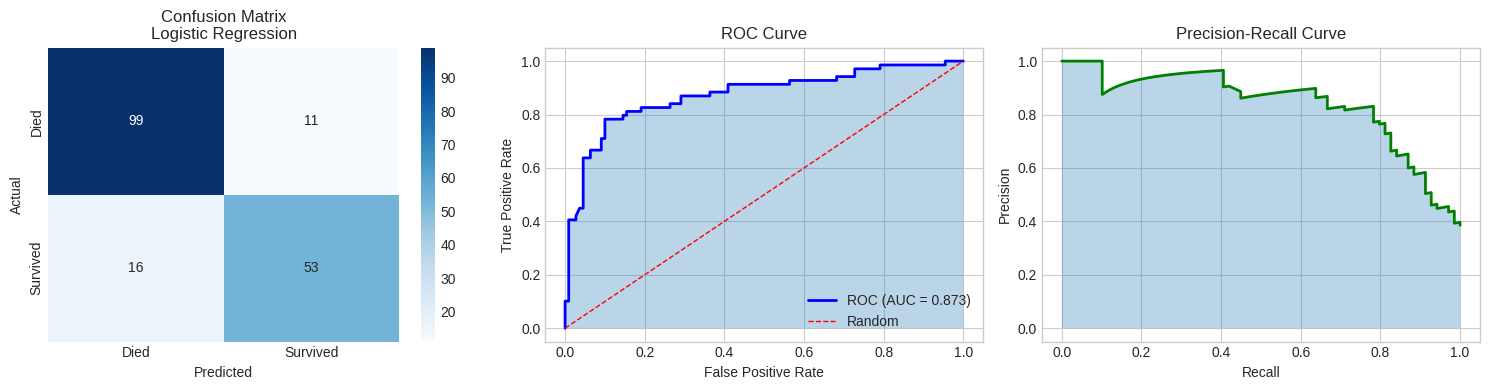


📋 Classification Report:
              precision    recall  f1-score   support

        Died       0.86      0.90      0.88       110
    Survived       0.83      0.77      0.80        69

    accuracy                           0.85       179
   macro avg       0.84      0.83      0.84       179
weighted avg       0.85      0.85      0.85       179



In [11]:
def plot_model_evaluation(y_true, y_pred, y_proba, model_name="Model"):
    """
    Create comprehensive visualization of model performance
    """
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    # 1. Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
                xticklabels=['Died', 'Survived'],
                yticklabels=['Died', 'Survived'])
    axes[0].set_xlabel('Predicted')
    axes[0].set_ylabel('Actual')
    axes[0].set_title(f'Confusion Matrix\n{model_name}')
    
    # 2. ROC Curve
    if y_proba is not None:
        fpr, tpr, _ = roc_curve(y_true, y_proba)
        auc = roc_auc_score(y_true, y_proba)
        axes[1].plot(fpr, tpr, 'b-', linewidth=2, label=f'ROC (AUC = {auc:.3f})')
        axes[1].plot([0, 1], [0, 1], 'r--', linewidth=1, label='Random')
        axes[1].fill_between(fpr, tpr, alpha=0.3)
        axes[1].set_xlabel('False Positive Rate')
        axes[1].set_ylabel('True Positive Rate')
        axes[1].set_title('ROC Curve')
        axes[1].legend(loc='lower right')
    
    # 3. Precision-Recall Curve
    if y_proba is not None:
        precision, recall, _ = precision_recall_curve(y_true, y_proba)
        axes[2].plot(recall, precision, 'g-', linewidth=2)
        axes[2].fill_between(recall, precision, alpha=0.3)
        axes[2].set_xlabel('Recall')
        axes[2].set_ylabel('Precision')
        axes[2].set_title('Precision-Recall Curve')
    
    plt.tight_layout()
    plt.show()
    
    # Classification Report
    print("\n📋 Classification Report:")
    print(classification_report(y_true, y_pred, target_names=['Died', 'Survived']))

# Visualize baseline model
plot_model_evaluation(y_val, y_val_pred, y_val_proba, "Logistic Regression")


---

## 5. Model Benchmarking - Compare Multiple Models

### 🏆 The Kaggle Approach

Professional Kagglers don't just try one model - they benchmark many!

**Common Models for Classification:**
1. **Logistic Regression** - Linear, interpretable baseline
2. **Decision Tree** - Non-linear, interpretable
3. **Random Forest** - Ensemble of trees, very robust
4. **Gradient Boosting** - Sequential improvement, often wins!
5. **SVM** - Good for high-dimensional data
6. **KNN** - Simple, distance-based
7. **Naive Bayes** - Fast, works well with less data

### Create Model Zoo


In [12]:
# ============= Define Model Zoo =============

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'AdaBoost': AdaBoostClassifier(random_state=42, algorithm='SAMME'),
    'Extra Trees': ExtraTreesClassifier(n_estimators=100, random_state=42),
    'SVM (RBF)': SVC(probability=True, random_state=42),
    'KNN': KNeighborsClassifier(),
    'Naive Bayes': GaussianNB()
}

print(f"🦁 Model Zoo: {len(models)} models ready for benchmarking!")
for name in models.keys():
    print(f"   • {name}")


🦁 Model Zoo: 9 models ready for benchmarking!
   • Logistic Regression
   • Decision Tree
   • Random Forest
   • Gradient Boosting
   • AdaBoost
   • Extra Trees
   • SVM (RBF)
   • KNN
   • Naive Bayes


### Train & Benchmark All Models

In [13]:
# ============= Benchmark All Models =============

benchmark_results = []
trained_pipelines = {}

print("🏃 Training all models...\n")

for name, model in models.items():
    # Create pipeline with same preprocessor
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    # Train
    pipeline.fit(X_train, y_train)
    trained_pipelines[name] = pipeline
    
    # Evaluate
    results, _, _ = evaluate_model(pipeline, X_train, y_train, X_val, y_val, name)
    benchmark_results.append(results)
    
    print(f"   ✓ {name}: Val Accuracy = {results['Val Accuracy']:.4f}")

# Create results DataFrame
benchmark_df = pd.DataFrame(benchmark_results)
benchmark_df = benchmark_df.sort_values('Val Accuracy', ascending=False)

print("\n✅ All models trained!")


🏃 Training all models...

   ✓ Logistic Regression: Val Accuracy = 0.8492
   ✓ Decision Tree: Val Accuracy = 0.7486
   ✓ Random Forest: Val Accuracy = 0.7821
   ✓ Gradient Boosting: Val Accuracy = 0.8212
   ✓ AdaBoost: Val Accuracy = 0.8156
   ✓ Extra Trees: Val Accuracy = 0.7542
   ✓ SVM (RBF): Val Accuracy = 0.8436
   ✓ KNN: Val Accuracy = 0.7933
   ✓ Naive Bayes: Val Accuracy = 0.7430

✅ All models trained!


In [14]:
# ============= Display Benchmark Results =============

print("🏆 MODEL BENCHMARK LEADERBOARD 🏆")
print("=" * 80)
print(benchmark_df.to_string(index=False))
print("=" * 80)

🏆 MODEL BENCHMARK LEADERBOARD 🏆
              Model  Train Accuracy  Val Accuracy  Val Precision  Val Recall   Val F1  Val ROC-AUC
Logistic Regression        0.838483      0.849162       0.828125    0.768116 0.796992     0.873386
          SVM (RBF)        0.832865      0.843575       0.825397    0.753623 0.787879     0.844796
  Gradient Boosting        0.912921      0.821229       0.813559    0.695652 0.750000     0.849341
           AdaBoost        0.835674      0.815642       0.750000    0.782609 0.765957     0.821212
                KNN        0.858146      0.793296       0.758065    0.681159 0.717557     0.807576
      Random Forest        0.987360      0.782123       0.758621    0.637681 0.692913     0.825362
        Extra Trees        0.987360      0.754190       0.692308    0.652174 0.671642     0.781357
      Decision Tree        0.987360      0.748603       0.671429    0.681159 0.676259     0.727536
        Naive Bayes        0.779494      0.743017       0.621053    0.855072 

### Visualize Benchmark Results

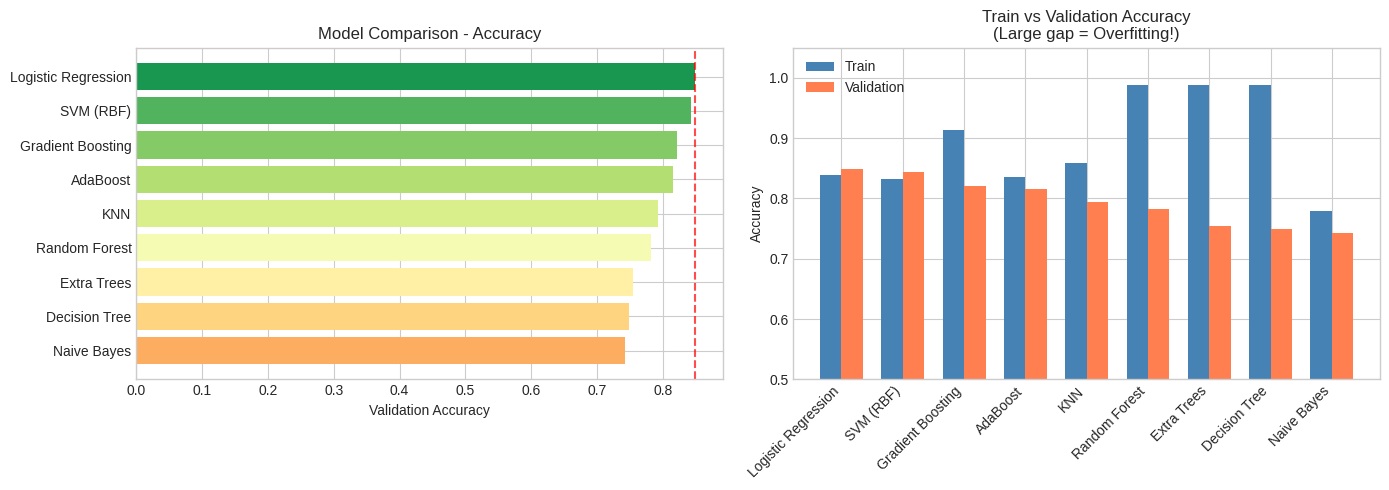


🥇 Best Model: Logistic Regression
   Validation Accuracy: 0.8492


In [15]:
# ============= Visualize Benchmark Results =============

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Accuracy comparison
colors = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(benchmark_df)))
benchmark_df_sorted = benchmark_df.sort_values('Val Accuracy')
axes[0].barh(benchmark_df_sorted['Model'], benchmark_df_sorted['Val Accuracy'], color=colors)
axes[0].set_xlabel('Validation Accuracy')
axes[0].set_title('Model Comparison - Accuracy')
axes[0].axvline(x=benchmark_df['Val Accuracy'].max(), color='red', linestyle='--', alpha=0.7)

# 2. Train vs Validation Accuracy (Overfitting Check!)
x = np.arange(len(benchmark_df))
width = 0.35
axes[1].bar(x - width/2, benchmark_df['Train Accuracy'], width, label='Train', color='steelblue')
axes[1].bar(x + width/2, benchmark_df['Val Accuracy'], width, label='Validation', color='coral')
axes[1].set_xticks(x)
axes[1].set_xticklabels(benchmark_df['Model'], rotation=45, ha='right')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Train vs Validation Accuracy\n(Large gap = Overfitting!)')
axes[1].legend()
axes[1].set_ylim(0.5, 1.05)

plt.tight_layout()
plt.show()

# Identify best model
best_model_name = benchmark_df.iloc[0]['Model']
print(f"\n🥇 Best Model: {best_model_name}")
print(f"   Validation Accuracy: {benchmark_df.iloc[0]['Val Accuracy']:.4f}")


### 🔄 Cross-Validation - More Robust Evaluation

**Problem with single train-val split:**
- Results depend on which data ends up in validation
- Might get lucky or unlucky

**Solution: K-Fold Cross-Validation**
- Split data into K parts (folds)
- Train K times, each time using a different fold for validation
- Average the results for more reliable estimate

```
Fold 1: [VAL] [Train] [Train] [Train] [Train]
Fold 2: [Train] [VAL] [Train] [Train] [Train]
Fold 3: [Train] [Train] [VAL] [Train] [Train]
Fold 4: [Train] [Train] [Train] [VAL] [Train]
Fold 5: [Train] [Train] [Train] [Train] [VAL]
```


In [16]:
# ============= Cross-Validation Benchmark =============

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

print("🔄 Running 5-Fold Cross-Validation...\n")

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    # Cross-validation scores
    scores = cross_val_score(pipeline, X, y, cv=cv, scoring='accuracy')
    
    cv_results.append({
        'Model': name,
        'CV Mean': scores.mean(),
        'CV Std': scores.std(),
        'CV Scores': scores
    })
    
    print(f"   {name}: {scores.mean():.4f} (+/- {scores.std()*2:.4f})")

cv_df = pd.DataFrame(cv_results).sort_values('CV Mean', ascending=False)
print("\n✅ Cross-validation complete!")


🔄 Running 5-Fold Cross-Validation...

   Logistic Regression: 0.8316 (+/- 0.0320)
   Decision Tree: 0.7744 (+/- 0.0510)
   Random Forest: 0.8137 (+/- 0.0196)
   Gradient Boosting: 0.8451 (+/- 0.0423)
   AdaBoost: 0.8227 (+/- 0.0253)
   Extra Trees: 0.7968 (+/- 0.0369)
   SVM (RBF): 0.8339 (+/- 0.0199)
   KNN: 0.8148 (+/- 0.0338)
   Naive Bayes: 0.7699 (+/- 0.0297)

✅ Cross-validation complete!


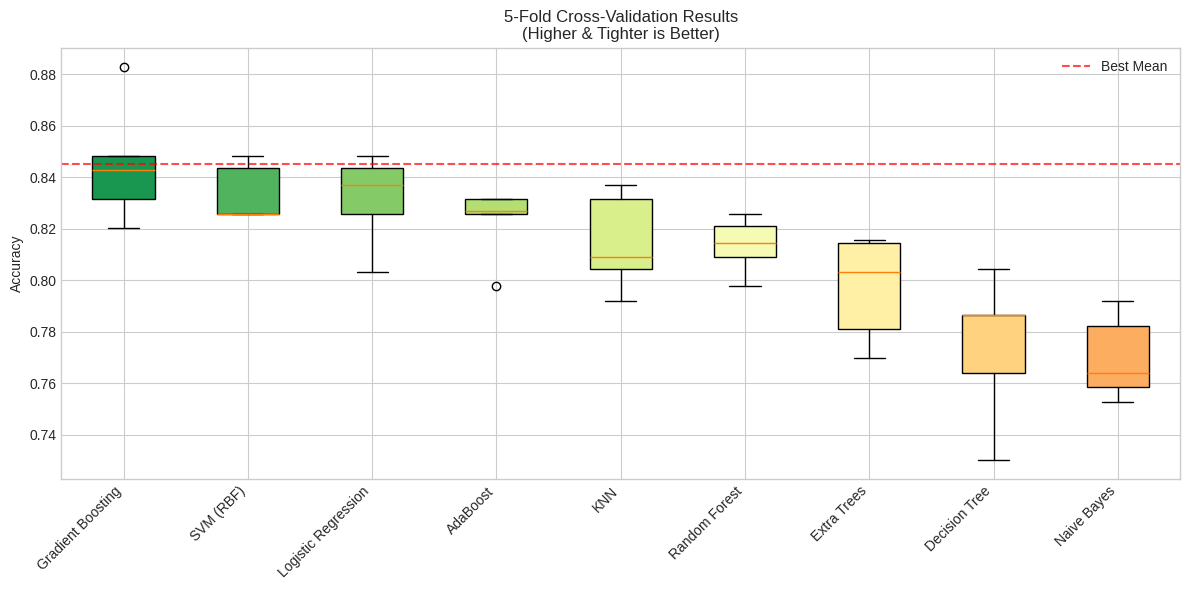


🏆 CV Leaderboard:
              Model  CV Mean   CV Std
  Gradient Boosting 0.845076 0.021134
          SVM (RBF) 0.833884 0.009961
Logistic Regression 0.831636 0.016018
           AdaBoost 0.822666 0.012670
                KNN 0.814826 0.016900
      Random Forest 0.813684 0.009813
        Extra Trees 0.796836 0.018464
      Decision Tree 0.774377 0.025482
        Naive Bayes 0.769908 0.014845


In [17]:
# ============= Visualize Cross-Validation Results =============

fig, ax = plt.subplots(figsize=(12, 6))

# Create box plot of CV scores
cv_scores_data = [r['CV Scores'] for r in cv_results]
cv_names = [r['Model'] for r in cv_results]

# Sort by mean
sorted_indices = np.argsort([np.mean(s) for s in cv_scores_data])[::-1]
cv_scores_sorted = [cv_scores_data[i] for i in sorted_indices]
cv_names_sorted = [cv_names[i] for i in sorted_indices]

bp = ax.boxplot(cv_scores_sorted, labels=cv_names_sorted, patch_artist=True)

# Color the boxes
colors = plt.cm.RdYlGn(np.linspace(0.9, 0.3, len(cv_names_sorted)))
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)

ax.set_xticklabels(cv_names_sorted, rotation=45, ha='right')
ax.set_ylabel('Accuracy')
ax.set_title('5-Fold Cross-Validation Results\n(Higher & Tighter is Better)')
ax.axhline(y=cv_df['CV Mean'].max(), color='red', linestyle='--', alpha=0.7, label='Best Mean')
ax.legend()

plt.tight_layout()
plt.show()

print("\n🏆 CV Leaderboard:")
print(cv_df[['Model', 'CV Mean', 'CV Std']].to_string(index=False))


---

## 6. Understanding Bias, Variance, Overfitting & Underfitting

### 🎯 The Core ML Concepts

This is **THE MOST IMPORTANT** concept in machine learning!

### Bias vs Variance

| Concept | What it means | Symptoms |
|---------|---------------|----------|
| **High Bias** | Model is too simple | Low train accuracy, Low val accuracy |
| **High Variance** | Model is too complex | High train accuracy, Low val accuracy |
| **Good Balance** | Just right! | Similar train & val accuracy (both high) |

### Overfitting vs Underfitting

```
                           Training Acc    Validation Acc
UNDERFITTING (High Bias):    LOW ❌          LOW ❌
   → Model is too simple, can't learn patterns

GOOD FIT:                    HIGH ✅         HIGH ✅
   → Model generalizes well!

OVERFITTING (High Variance): VERY HIGH ✅    LOW ❌
   → Model memorized training data, doesn't generalize
```

### 🔍 Visual Intuition

```
Underfitting          Good Fit            Overfitting
(High Bias)                               (High Variance)

     |    .           |    .              |    .
     | .    .         | .-----.           | .~~~~~.
 y   |----            |/       \      y   |/       \
     |    .           |    .    .         |    .
     |________        |__________         |__________
        x                 x                   x

Too simple!          Just right!         Too complex!
```


### Diagnose with Learning Curves

Learning curves show how model performance changes with training data size:

In [18]:
def plot_learning_curve(estimator, X, y, title, cv=5):
    """
    Plot learning curve to diagnose bias/variance
    """
    train_sizes, train_scores, val_scores = learning_curve(
        estimator, X, y,
        train_sizes=np.linspace(0.1, 1.0, 10),
        cv=cv, scoring='accuracy', n_jobs=-1
    )
    
    train_mean = train_scores.mean(axis=1)
    train_std = train_scores.std(axis=1)
    val_mean = val_scores.mean(axis=1)
    val_std = val_scores.std(axis=1)
    
    plt.figure(figsize=(10, 6))
    
    # Plot training score
    plt.plot(train_sizes, train_mean, 'o-', color='blue', label='Training Score')
    plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, 
                     alpha=0.1, color='blue')
    
    # Plot validation score
    plt.plot(train_sizes, val_mean, 'o-', color='red', label='Validation Score')
    plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, 
                     alpha=0.1, color='red')
    
    plt.xlabel('Training Set Size')
    plt.ylabel('Accuracy')
    plt.title(f'Learning Curve: {title}')
    plt.legend(loc='lower right')
    plt.grid(True, alpha=0.3)
    
    # Add diagnosis
    gap = train_mean[-1] - val_mean[-1]
    if gap > 0.1:
        diagnosis = "⚠️ HIGH VARIANCE (Overfitting) - Consider regularization or more data"
    elif train_mean[-1] < 0.75:
        diagnosis = "⚠️ HIGH BIAS (Underfitting) - Consider more features or complex model"
    else:
        diagnosis = "✅ GOOD FIT - Model generalizes well!"
    
    plt.figtext(0.5, -0.05, diagnosis, ha='center', fontsize=12, 
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    plt.tight_layout()
    plt.show()
    
    return train_mean[-1], val_mean[-1], gap


### Demo: Underfitting vs Overfitting with Decision Tree

Decision Trees are perfect for demonstrating this because we can control complexity with `max_depth`:


In [19]:
# ============= Demonstrate Underfitting vs Overfitting =============

# Test different max_depth values
depths = [1, 2, 3, 5, 10, 20, None]  # None = unlimited depth
depth_results = []

print("🌳 Decision Tree: Effect of max_depth\n")
print(f"{'max_depth':<12} {'Train Acc':<12} {'Val Acc':<12} {'Gap':<12} {'Diagnosis'}")
print("-" * 60)

for depth in depths:
    # Create pipeline
    dt_pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(max_depth=depth, random_state=42))
    ])
    
    # Fit and evaluate
    dt_pipeline.fit(X_train, y_train)
    train_acc = dt_pipeline.score(X_train, y_train)
    val_acc = dt_pipeline.score(X_val, y_val)
    gap = train_acc - val_acc
    
    # Diagnosis
    if gap > 0.15:
        diagnosis = "🔴 Overfitting"
    elif train_acc < 0.75:
        diagnosis = "🟡 Underfitting"
    else:
        diagnosis = "🟢 Good"
    
    depth_str = str(depth) if depth else "None"
    print(f"{depth_str:<12} {train_acc:<12.4f} {val_acc:<12.4f} {gap:<12.4f} {diagnosis}")
    
    depth_results.append({
        'max_depth': depth if depth else 50,
        'train_acc': train_acc,
        'val_acc': val_acc
    })


🌳 Decision Tree: Effect of max_depth

max_depth    Train Acc    Val Acc      Gap          Diagnosis
------------------------------------------------------------
1            0.7851       0.7709       0.0142       🟢 Good
2            0.7949       0.7654       0.0296       🟢 Good
3            0.8315       0.8324       -0.0009      🟢 Good
5            0.8666       0.8101       0.0565       🟢 Good
10           0.9382       0.8101       0.1281       🟢 Good
20           0.9860       0.7486       0.2374       🔴 Overfitting
None         0.9874       0.7486       0.2388       🔴 Overfitting


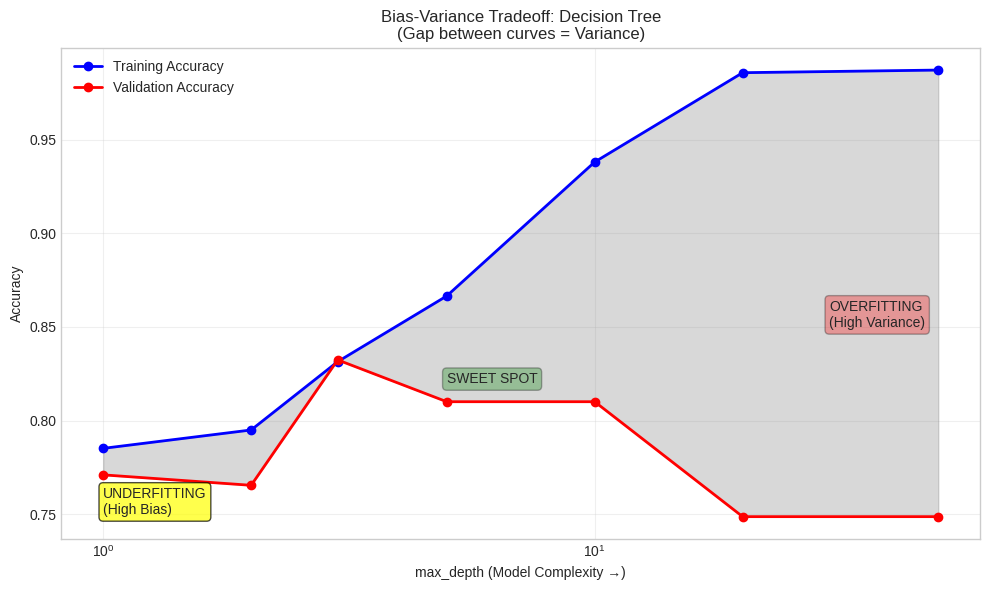


💡 KEY INSIGHT:
   • As max_depth increases, model becomes more complex
   • Training accuracy keeps increasing (memorizing)
   • Validation accuracy peaks then drops (overfitting)
   • Find the 'sweet spot' where both are high!


In [20]:
# ============= Visualize Bias-Variance Tradeoff =============

depth_df = pd.DataFrame(depth_results)

plt.figure(figsize=(10, 6))
plt.plot(depth_df['max_depth'], depth_df['train_acc'], 'b-o', label='Training Accuracy', linewidth=2)
plt.plot(depth_df['max_depth'], depth_df['val_acc'], 'r-o', label='Validation Accuracy', linewidth=2)
plt.fill_between(depth_df['max_depth'], depth_df['train_acc'], depth_df['val_acc'], alpha=0.3, color='gray')

plt.xlabel('max_depth (Model Complexity →)')
plt.ylabel('Accuracy')
plt.title('Bias-Variance Tradeoff: Decision Tree\n(Gap between curves = Variance)')
plt.legend()

# Add annotations
plt.annotate('UNDERFITTING\n(High Bias)', xy=(1, 0.75), fontsize=10, 
             bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.7))
plt.annotate('OVERFITTING\n(High Variance)', xy=(30, 0.85), fontsize=10,
             bbox=dict(boxstyle='round', facecolor='red', alpha=0.3))
plt.annotate('SWEET SPOT', xy=(5, 0.82), fontsize=10,
             bbox=dict(boxstyle='round', facecolor='green', alpha=0.3))

plt.xscale('log')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\n💡 KEY INSIGHT:")
print("   • As max_depth increases, model becomes more complex")
print("   • Training accuracy keeps increasing (memorizing)")
print("   • Validation accuracy peaks then drops (overfitting)")
print("   • Find the 'sweet spot' where both are high!")


### Learning Curve of Random Forest (Our Best Model)

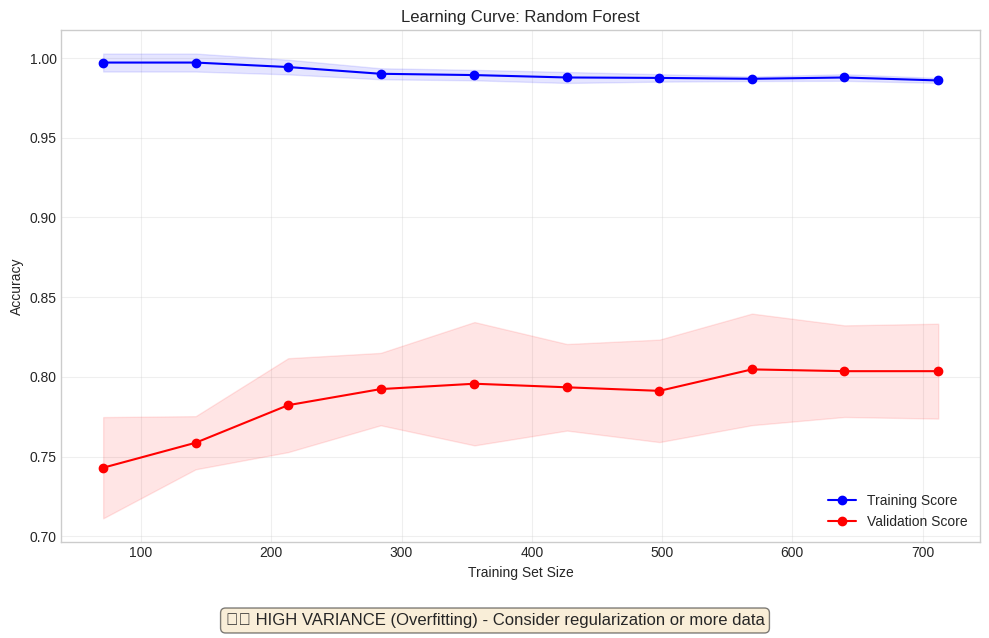

In [21]:
# Create Random Forest pipeline for learning curve
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])

# Plot learning curve
train_score, val_score, gap = plot_learning_curve(
    rf_pipeline, X, y, 
    "Random Forest", cv=5
)


### 🔧 How to Fix Overfitting/Underfitting

| Problem | Solutions |
|---------|-----------|
| **Underfitting** | • Use more complex model<br>• Add more features<br>• Reduce regularization<br>• Feature engineering |
| **Overfitting** | • Simplify model<br>• Add regularization<br>• Get more training data<br>• Feature selection<br>• Cross-validation |

---

## 7. Hyperparameter Tuning - Finding the Optimal Settings

### 🎛️ What are Hyperparameters?

**Parameters** = Learned from data (e.g., weights in neural network)
**Hyperparameters** = Set by us BEFORE training (e.g., learning rate, max_depth)

### Common Hyperparameters by Model

| Model | Key Hyperparameters |
|-------|---------------------|
| **Logistic Regression** | C (regularization), solver |
| **Decision Tree** | max_depth, min_samples_split, min_samples_leaf |
| **Random Forest** | n_estimators, max_depth, max_features |
| **Gradient Boosting** | n_estimators, learning_rate, max_depth |
| **SVM** | C, kernel, gamma |
| **KNN** | n_neighbors, weights |


### Method 1: GridSearchCV - Exhaustive Search

Try ALL combinations of hyperparameters:


In [22]:
# ============= GridSearchCV for Random Forest =============

# Define the pipeline
rf_pipeline_tune = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

# Define parameter grid
# Note: Use 'classifier__' prefix to access classifier parameters in pipeline
param_grid = {
    'classifier__n_estimators': [50, 100, 200],
    'classifier__max_depth': [3, 5, 7, 10, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

# Calculate total combinations
n_combinations = 1
for v in param_grid.values():
    n_combinations *= len(v)
print(f"🔍 GridSearchCV will try {n_combinations} combinations!")
print(f"   With 5-fold CV, that's {n_combinations * 5} model fits!\n")

# Run GridSearchCV
grid_search = GridSearchCV(
    rf_pipeline_tune,
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,  # Use all CPU cores
    verbose=1
)

print("⏳ Running GridSearchCV (this may take a minute)...")
grid_search.fit(X_train, y_train)

print(f"\n✅ Best parameters found!")
print(f"   Best CV Score: {grid_search.best_score_:.4f}")


🔍 GridSearchCV will try 135 combinations!
   With 5-fold CV, that's 675 model fits!

⏳ Running GridSearchCV (this may take a minute)...
Fitting 5 folds for each of 135 candidates, totalling 675 fits

✅ Best parameters found!
   Best CV Score: 0.8357


In [23]:
# ============= Display Best Parameters =============

print("🏆 Best Hyperparameters:")
for param, value in grid_search.best_params_.items():
    print(f"   {param}: {value}")

# Evaluate best model
best_rf = grid_search.best_estimator_
train_acc = best_rf.score(X_train, y_train)
val_acc = best_rf.score(X_val, y_val)

print(f"\n📊 Performance:")
print(f"   Training Accuracy: {train_acc:.4f}")
print(f"   Validation Accuracy: {val_acc:.4f}")
print(f"   Improvement over default: +{(val_acc - benchmark_df[benchmark_df['Model']=='Random Forest']['Val Accuracy'].values[0]):.4f}")


🏆 Best Hyperparameters:
   classifier__max_depth: None
   classifier__min_samples_leaf: 1
   classifier__min_samples_split: 10
   classifier__n_estimators: 50

📊 Performance:
   Training Accuracy: 0.9087
   Validation Accuracy: 0.8045
   Improvement over default: +0.0223


### Method 2: RandomizedSearchCV - Smart Random Search

When parameter space is large, try random combinations instead:
- Faster than GridSearch
- Often finds good solutions with fewer iterations
- Use distributions instead of fixed lists


In [24]:
# ============= RandomizedSearchCV for Gradient Boosting =============

from scipy.stats import randint, uniform

# Define pipeline
gb_pipeline_tune = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(random_state=42))
])

# Define parameter distributions (not fixed lists!)
param_distributions = {
    'classifier__n_estimators': randint(50, 300),
    'classifier__learning_rate': uniform(0.01, 0.29),  # 0.01 to 0.30
    'classifier__max_depth': randint(2, 10),
    'classifier__min_samples_split': randint(2, 20),
    'classifier__min_samples_leaf': randint(1, 10),
    'classifier__subsample': uniform(0.6, 0.4)  # 0.6 to 1.0
}

# Run RandomizedSearchCV
random_search = RandomizedSearchCV(
    gb_pipeline_tune,
    param_distributions,
    n_iter=50,  # Try 50 random combinations
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

print("⏳ Running RandomizedSearchCV (50 random combinations)...")
random_search.fit(X_train, y_train)

print(f"\n✅ Best parameters found!")
print(f"   Best CV Score: {random_search.best_score_:.4f}")


⏳ Running RandomizedSearchCV (50 random combinations)...
Fitting 5 folds for each of 50 candidates, totalling 250 fits

✅ Best parameters found!
   Best CV Score: 0.8273


In [25]:
# ============= Display RandomizedSearch Results =============

print("🏆 Best Gradient Boosting Hyperparameters:")
for param, value in random_search.best_params_.items():
    if isinstance(value, float):
        print(f"   {param}: {value:.4f}")
    else:
        print(f"   {param}: {value}")

# Evaluate
best_gb = random_search.best_estimator_
train_acc = best_gb.score(X_train, y_train)
val_acc = best_gb.score(X_val, y_val)

print(f"\n📊 Performance:")
print(f"   Training Accuracy: {train_acc:.4f}")
print(f"   Validation Accuracy: {val_acc:.4f}")


🏆 Best Gradient Boosting Hyperparameters:
   classifier__learning_rate: 0.0102
   classifier__max_depth: 6
   classifier__min_samples_leaf: 9
   classifier__min_samples_split: 4
   classifier__n_estimators: 152
   classifier__subsample: 0.6659

📊 Performance:
   Training Accuracy: 0.8904
   Validation Accuracy: 0.8212


---

## 8. Advanced Techniques - Ensemble Methods

### 🎭 The Power of Ensembles

**Idea:** Combine multiple models to get better predictions than any single model!

**Why it works:**
- Different models make different errors
- Combining them averages out errors
- "Wisdom of the crowd"

### Types of Ensembles

| Method | How it works | When to use |
|--------|--------------|-------------|
| **Voting** | Models vote on prediction | Different model types |
| **Bagging** | Train same model on different data samples | Reduce variance |
| **Boosting** | Sequential models fix previous errors | Reduce bias |
| **Stacking** | Use model predictions as features for meta-model | Maximum performance |


### Voting Classifier - Democracy of Models!


In [26]:
# ============= Voting Classifier =============

# Select our best individual models
voting_clf = VotingClassifier(
    estimators=[
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
        ('gb', GradientBoostingClassifier(random_state=42)),
        ('lr', LogisticRegression(max_iter=1000, random_state=42)),
        ('svc', SVC(probability=True, random_state=42))
    ],
    voting='soft'  # Use probability averaging (better than hard voting)
)

# Create pipeline
voting_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', voting_clf)
])

# Train and evaluate
print("🗳️ Training Voting Classifier...")
voting_pipeline.fit(X_train, y_train)

train_acc = voting_pipeline.score(X_train, y_train)
val_acc = voting_pipeline.score(X_val, y_val)

print(f"\n📊 Voting Classifier Results:")
print(f"   Training Accuracy: {train_acc:.4f}")
print(f"   Validation Accuracy: {val_acc:.4f}")


🗳️ Training Voting Classifier...

📊 Voting Classifier Results:
   Training Accuracy: 0.8904
   Validation Accuracy: 0.8380


### Stacking Classifier - The Professional's Choice

Stacking uses predictions from base models as features for a meta-model:

```
              ┌─────────────┐
              │  Raw Data   │
              └──────┬──────┘
         ┌──────────┼──────────┐
         ▼          ▼          ▼
      ┌──────┐  ┌──────┐  ┌──────┐
      │Model1│  │Model2│  │Model3│    ← Base Models
      └──┬───┘  └──┬───┘  └──┬───┘
         │         │         │
         ▼         ▼         ▼
      ┌────────────────────────┐
      │  Predictions (features)│
      └───────────┬────────────┘
                  ▼
            ┌──────────┐
            │Meta Model│             ← Final Prediction
            └──────────┘
```


In [27]:
# ============= Stacking Classifier =============

# Base models (diverse is better!)
base_models = [
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
    ('gb', GradientBoostingClassifier(random_state=42)),
    ('et', ExtraTreesClassifier(n_estimators=100, random_state=42)),
    ('svc', SVC(probability=True, random_state=42))
]

# Meta model (simple is usually better)
meta_model = LogisticRegression(max_iter=1000)

# Create stacking classifier
stacking_clf = StackingClassifier(
    estimators=base_models,
    final_estimator=meta_model,
    cv=5,
    passthrough=True  # Also include original features
)

# Create pipeline
stacking_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', stacking_clf)
])

# Train and evaluate
print("📚 Training Stacking Classifier (this takes a bit longer)...")
stacking_pipeline.fit(X_train, y_train)

train_acc = stacking_pipeline.score(X_train, y_train)
val_acc = stacking_pipeline.score(X_val, y_val)

print(f"\n📊 Stacking Classifier Results:")
print(f"   Training Accuracy: {train_acc:.4f}")
print(f"   Validation Accuracy: {val_acc:.4f}")


📚 Training Stacking Classifier (this takes a bit longer)...

📊 Stacking Classifier Results:
   Training Accuracy: 0.8947
   Validation Accuracy: 0.8380


---

## 9. Feature Importance - What Matters Most?

Understanding which features are most predictive helps you:
1. Build better models
2. Create better features
3. Explain your model to others


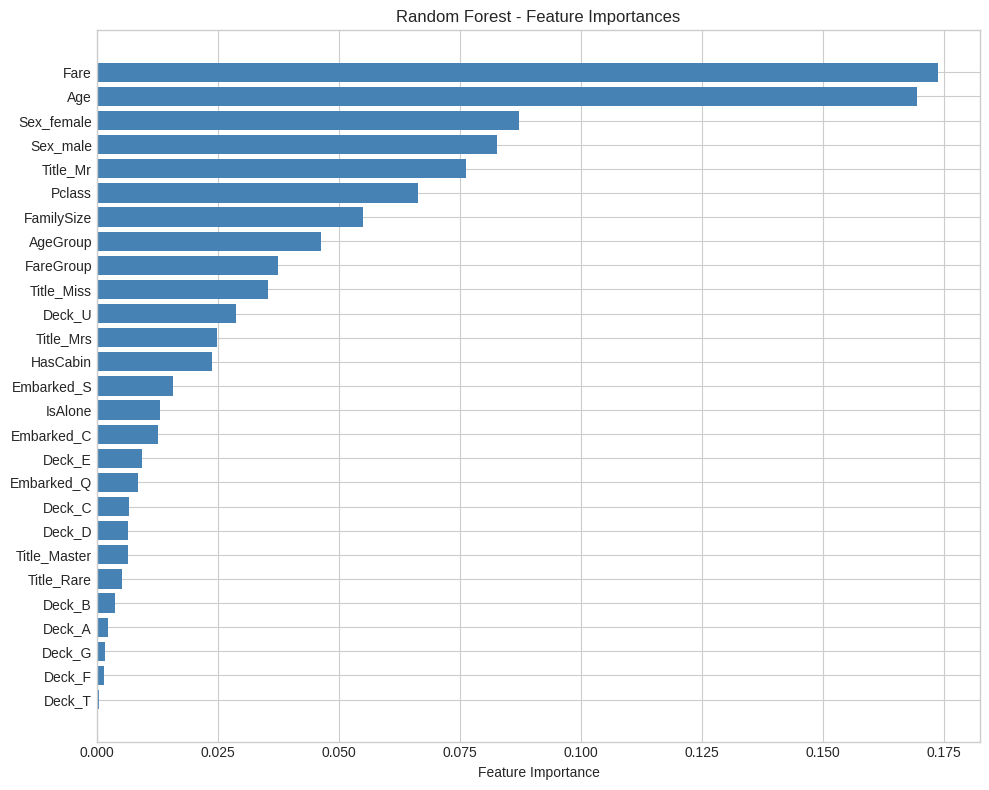


🏆 Top 10 Most Important Features:
   Fare: 0.1737
   Age: 0.1694
   Sex_female: 0.0871
   Sex_male: 0.0826
   Title_Mr: 0.0763
   Pclass: 0.0663
   FamilySize: 0.0550
   AgeGroup: 0.0462
   FareGroup: 0.0373
   Title_Miss: 0.0354


In [28]:
# ============= Feature Importance from Random Forest =============

# Get feature names after preprocessing
# This is a bit tricky with ColumnTransformer
def get_feature_names(column_transformer, original_features):
    """Extract feature names from a ColumnTransformer"""
    feature_names = []
    
    for name, transformer, columns in column_transformer.transformers_:
        if name == 'remainder':
            continue
        if hasattr(transformer, 'get_feature_names_out'):
            # For OneHotEncoder
            names = transformer.get_feature_names_out(columns)
            feature_names.extend(names)
        elif name == 'bin':
            # Passthrough
            feature_names.extend(columns)
        else:
            # For other transformers
            feature_names.extend(columns)
    
    return feature_names

# Fit a simple Random Forest to get feature importances
rf_simple = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])
rf_simple.fit(X_train, y_train)

# Get feature importances
importances = rf_simple.named_steps['classifier'].feature_importances_

# Get feature names (simplified approach)
feature_names = (
    numerical_features + 
    [f"{col}_{cat}" for col in categorical_features for cat in ['encoded']] + 
    ordinal_features + 
    binary_features
)

# For proper names, let's use a simpler approach
n_features = len(importances)
try:
    # Try to get actual feature names
    ohe = preprocessor.named_transformers_['cat'].named_steps['onehot']
    cat_feature_names = list(ohe.get_feature_names_out(categorical_features))
    feature_names = numerical_features + cat_feature_names + ordinal_features + binary_features
except:
    feature_names = [f"feature_{i}" for i in range(n_features)]

# Create DataFrame for visualization
importance_df = pd.DataFrame({
    'Feature': feature_names[:len(importances)],
    'Importance': importances
}).sort_values('Importance', ascending=True)

# Plot
plt.figure(figsize=(10, 8))
plt.barh(importance_df['Feature'], importance_df['Importance'], color='steelblue')
plt.xlabel('Feature Importance')
plt.title('Random Forest - Feature Importances')
plt.tight_layout()
plt.show()

# Top features
print("\n🏆 Top 10 Most Important Features:")
for i, row in importance_df.tail(10).iloc[::-1].iterrows():
    print(f"   {row['Feature']}: {row['Importance']:.4f}")


---

## 10. Final Model Comparison & Selection


In [29]:
# ============= Final Model Comparison =============

final_models = {
    'Logistic Regression (Baseline)': baseline_pipeline,
    'Random Forest (Default)': trained_pipelines['Random Forest'],
    'Random Forest (Tuned)': best_rf,
    'Gradient Boosting (Tuned)': best_gb,
    'Voting Ensemble': voting_pipeline,
    'Stacking Ensemble': stacking_pipeline
}

final_results = []

print("🏆 FINAL MODEL COMPARISON")
print("=" * 70)

for name, model in final_models.items():
    train_acc = model.score(X_train, y_train)
    val_acc = model.score(X_val, y_val)
    
    # Cross-validation for more robust estimate
    cv_scores = cross_val_score(model, X, y, cv=5, scoring='accuracy')
    
    final_results.append({
        'Model': name,
        'Train Acc': train_acc,
        'Val Acc': val_acc,
        'CV Mean': cv_scores.mean(),
        'CV Std': cv_scores.std()
    })
    
    print(f"\n{name}:")
    print(f"   Train: {train_acc:.4f} | Val: {val_acc:.4f} | CV: {cv_scores.mean():.4f} (+/- {cv_scores.std()*2:.4f})")

final_df = pd.DataFrame(final_results).sort_values('CV Mean', ascending=False)
print("\n" + "=" * 70)


🏆 FINAL MODEL COMPARISON

Logistic Regression (Baseline):
   Train: 0.8385 | Val: 0.8492 | CV: 0.8283 (+/- 0.0365)

Random Forest (Default):
   Train: 0.9874 | Val: 0.7821 | CV: 0.8025 (+/- 0.0626)

Random Forest (Tuned):
   Train: 0.9087 | Val: 0.8045 | CV: 0.8283 (+/- 0.0583)

Gradient Boosting (Tuned):
   Train: 0.8904 | Val: 0.8212 | CV: 0.8339 (+/- 0.0580)

Voting Ensemble:
   Train: 0.8904 | Val: 0.8380 | CV: 0.8429 (+/- 0.0385)

Stacking Ensemble:
   Train: 0.8947 | Val: 0.8380 | CV: 0.8283 (+/- 0.0441)



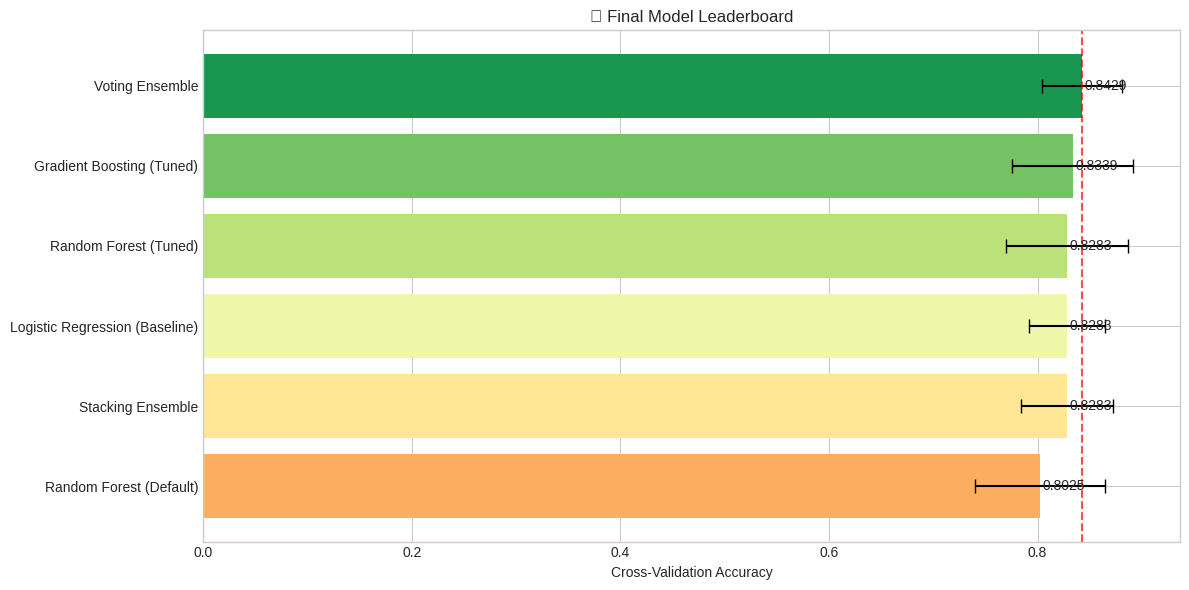


🥇 WINNER: Voting Ensemble
   Cross-Validation Score: 0.8429


In [30]:
# ============= Visualize Final Results =============

fig, ax = plt.subplots(figsize=(12, 6))

# Sort by CV Mean
final_df_sorted = final_df.sort_values('CV Mean')

# Create bar chart
colors = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(final_df_sorted)))
bars = ax.barh(final_df_sorted['Model'], final_df_sorted['CV Mean'], 
               xerr=final_df_sorted['CV Std']*2, color=colors, capsize=5)

ax.set_xlabel('Cross-Validation Accuracy')
ax.set_title('🏆 Final Model Leaderboard')
ax.axvline(x=final_df_sorted['CV Mean'].max(), color='red', linestyle='--', 
           alpha=0.7, label='Best Score')

# Add value labels
for bar, val in zip(bars, final_df_sorted['CV Mean']):
    ax.text(val + 0.002, bar.get_y() + bar.get_height()/2, 
            f'{val:.4f}', va='center', fontsize=10)

plt.tight_layout()
plt.show()

# Announce winner
best_model_name = final_df_sorted.iloc[-1]['Model']
best_score = final_df_sorted.iloc[-1]['CV Mean']
print(f"\n🥇 WINNER: {best_model_name}")
print(f"   Cross-Validation Score: {best_score:.4f}")


---

## 11. Kaggle Submission - The Final Step!

### 🚀 Creating Your Submission File

Kaggle expects a CSV file with:
- `PassengerId` - from test.csv
- `Survived` - your predictions (0 or 1)


In [32]:
# ============= Train Final Model on ALL Data =============

# Pro tip: Train on ALL training data before making test predictions!
# We've already validated our model, now we want to use every data point.

# Select our best model
final_model = voting_pipeline  # or use voting_pipeline, best_rf, etc.

# Retrain on full dataset
print("🔧 Training final model on ALL training data...")
final_model.fit(X, y)

# Make predictions on test set
test_predictions = final_model.predict(X_test_final)

print(f"✅ Predictions made for {len(test_predictions)} passengers")
print(f"   Predicted survivors: {test_predictions.sum()} ({test_predictions.mean()*100:.1f}%)")
print(f"   Predicted deaths: {len(test_predictions) - test_predictions.sum()} ({(1-test_predictions.mean())*100:.1f}%)")


🔧 Training final model on ALL training data...
✅ Predictions made for 418 passengers
   Predicted survivors: 154 (36.8%)
   Predicted deaths: 264 (63.2%)


In [33]:
# ============= Create Submission File =============

submission = pd.DataFrame({
    'PassengerId': test_passenger_ids,
    'Survived': test_predictions
})

# Save to CSV
submission.to_csv('submission.csv', index=False)

print("📁 Submission file created: submission.csv")
print(f"\n📊 Submission Preview:")
print(submission.head(10))

# Verify format
print(f"\n✅ Verification:")
print(f"   Shape: {submission.shape} (should be 418 rows, 2 columns)")
print(f"   Columns: {submission.columns.tolist()}")
print(f"   No missing values: {submission.isnull().sum().sum() == 0}")


📁 Submission file created: submission.csv

📊 Submission Preview:
   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         0
4          896         1
5          897         0
6          898         1
7          899         0
8          900         1
9          901         0

✅ Verification:
   Shape: (418, 2) (should be 418 rows, 2 columns)
   Columns: ['PassengerId', 'Survived']
   No missing values: True


---

## 12. 🏆 Pro Kaggle Tips & Tricks

### The Secrets of Top Kagglers

**1. Data Quality > Model Complexity**
```
Good features + Simple model >> Bad features + Complex model
```

**2. The Iteration Loop**
```
EDA → Feature Engineering → Model → Evaluate → Repeat
              ↑__________________________________|
```

**3. Cross-Validation is KING**
- Never trust a single train-test split
- Use Stratified K-Fold for classification
- Your CV score should match leaderboard score

**4. Ensemble Everything**
- Blend multiple models
- Even simple averaging helps
- Diversity is key!

**5. Feature Engineering Ideas**
- Interactions: `feature1 * feature2`
- Ratios: `feature1 / feature2`
- Polynomials: `feature^2`
- Binning continuous variables
- Target encoding (careful with leakage!)

**6. Hyperparameter Tuning Strategy**
1. Start with defaults
2. Coarse grid search
3. Fine-tune around best params
4. Consider Optuna/Hyperopt for complex spaces

**7. Avoid Data Leakage**
- Always use pipelines
- Split BEFORE any preprocessing
- Be careful with target encoding

**8. Track Everything**
- Keep a log of experiments
- Use version control
- Comment your code!

### Common Mistakes to Avoid

| Mistake | Why it's bad | Fix |
|---------|--------------|-----|
| Overfitting to validation | Model won't generalize | Use CV, not single split |
| Data leakage | Artificially good scores | Use pipelines |
| Not exploring data | Missing patterns | Thorough EDA |
| Complex model first | Hard to debug | Start simple |
| Ignoring feature engineering | Biggest impact | Spend time here |

---

## 13. Summary & Next Steps

### What You Learned Today

✅ **sklearn Pipelines & ColumnTransformer**
- Professional way to build ML workflows
- No data leakage, reproducible

✅ **Model Evaluation**
- Multiple metrics (Accuracy, Precision, Recall, F1, ROC-AUC)
- Confusion matrix interpretation
- Classification reports

✅ **Model Benchmarking**
- Compare multiple models systematically
- Cross-validation for robust estimates

✅ **Bias-Variance Tradeoff**
- Underfitting vs Overfitting
- Learning curves for diagnosis
- How to fix each problem

✅ **Hyperparameter Tuning**
- GridSearchCV for exhaustive search
- RandomizedSearchCV for large spaces

✅ **Ensemble Methods**
- Voting classifiers
- Stacking classifiers

✅ **Kaggle Submission**
- Proper file format
- Submission workflow

### Your Journey Forward

```
Beginner → Intermediate → Advanced → Kaggle Master
   ↑            ↑            ↑            ↑
 Today      Practice     Compete      Top 1%
            More         on Kaggle    Rankings
            Datasets
```

### Recommended Next Steps

1. **Submit to Kaggle!** - See your leaderboard position
2. **Try more feature engineering** - Can you improve your score?
3. **Explore other competitions** - Housing prices, Fraud detection
4. **Learn XGBoost/LightGBM** - State-of-the-art boosting
5. **Study winning solutions** - Learn from the best!

---

## 🎓 Workshop Complete!

**Congratulations!** You now have the skills to:
- Build professional ML pipelines
- Evaluate and compare models properly
- Tune hyperparameters like a pro
- Create ensemble models
- Submit predictions to Kaggle

**Remember:** Kaggle is about practice. The more competitions you enter, the better you'll get!

---

### Resources

- [Kaggle Learn](https://www.kaggle.com/learn) - Free ML courses
- [sklearn Documentation](https://scikit-learn.org/stable/documentation.html)
- [Kaggle Discussion Forums](https://www.kaggle.com/discussions) - Learn from others

---

**Happy Kaggling! 🚀**

*UIU Data Science Club - Building Bangladesh's Data Science Community*


---

## 📦 Bonus: Save Your Model for Later


In [34]:
# ============= Save Model =============
import joblib

# Save the trained pipeline
joblib.dump(final_model, 'titanic_model.joblib')
print("✅ Model saved to 'titanic_model.joblib'")

# To load later:
# loaded_model = joblib.load('titanic_model.joblib')
# predictions = loaded_model.predict(new_data)


✅ Model saved to 'titanic_model.joblib'


---

## 📋 Quick Reference Card

### Pipeline Template
```python
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Preprocessor
preprocessor = ColumnTransformer([
    ('num', numerical_transformer, numerical_cols),
    ('cat', categorical_transformer, categorical_cols)
])

# Full Pipeline
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', YourModel())
])

pipeline.fit(X_train, y_train)
predictions = pipeline.predict(X_test)
```

### Cross-Validation Template
```python
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(pipeline, X, y, cv=cv, scoring='accuracy')
print(f"CV Score: {scores.mean():.4f} (+/- {scores.std()*2:.4f})")
```

### GridSearch Template
```python
from sklearn.model_selection import GridSearchCV

param_grid = {
    'classifier__param1': [val1, val2],
    'classifier__param2': [val3, val4]
}

grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train)

print(grid_search.best_params_)
print(grid_search.best_score_)
```

### Ensemble Template
```python
from sklearn.ensemble import VotingClassifier, StackingClassifier

# Voting
voting = VotingClassifier([
    ('model1', Model1()),
    ('model2', Model2())
], voting='soft')

# Stacking
stacking = StackingClassifier(
    estimators=[('model1', Model1()), ('model2', Model2())],
    final_estimator=LogisticRegression()
)
```

### Submission Template
```python
predictions = model.predict(X_test)
submission = pd.DataFrame({
    'Id': test_ids,
    'Target': predictions
})
submission.to_csv('submission.csv', index=False)
```
